<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project3_tsunami.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Tsunami
In this project, we will use Dedalus to model the propagation of Tsunami waves. Tsunami typically have wavelengths larger than 100km and periods of about 1 hour. Since their wavelength is much larger than the depth of the ocean, Tsunami can be modelled using the shallow water equations. 

Here, we will use Dedalus to solve an initial value problem for the shallow water equations. We will generate a Tsunami using a localized disturbance to the water height. 

Student tasks are in [Section 1.3]( #section1pt3 ), [Section 2.3]( #section2pt3 ), and [Section 3.3]( #section3pt3 ).

## Setup
If you are using Google colab, run the script below to install Dedalus

In [1]:
# Set environment variables for best performance
%env OMP_NUM_THREADS=1
%env NUMEXPR_MAX_THREADS=1

# Minimize logging output
import logging
logging.disable(logging.DEBUG)

env: OMP_NUM_THREADS=1
env: NUMEXPR_MAX_THREADS=1


In [ ]:
# Set environment variables for best performance
%env OMP_NUM_THREADS=1
%env NUMEXPR_MAX_THREADS=1

# Minimize logging output
import logging
logging.disable(logging.DEBUG)

# Check if running on google colab
import os
using_google_colab = bool(os.getenv("COLAB_RELEASE_TAG"))

# Check for Dedalus
try:
    import dedalus.public as de
    print("Dedalus already installed :)")
except:
    print("Dedalus not installed yet.")
    if using_google_colab:
        print("Installing for Google Colab.")
        print()
        # Step 1: Install FFTW
        !apt-get install libfftw3-dev
        !apt-get install libfftw3-mpi-dev
        # Step 2: Set paths for Dedalus installation
        import os
        os.environ['MPI_INCLUDE_PATH'] = "/usr/lib/x86_64-linux-gnu/openmpi/include"
        os.environ['MPI_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        os.environ['FFTW_INCLUDE_PATH'] = "/usr/include"
        os.environ['FFTW_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        # Step 3: Install Dedalus using pip
        !pip3 install cython "mpi4py<4.0" numpy setuptools wheel
        !CC=mpicc pip3 install --no-cache --no-build-isolation http://github.com/dedalusproject/dedalus/zipball/master/
        !pip3 install -q ipympl
        # Step 4: Check installation
        print()
        try:
            import dedalus.public as de
            print("Dedalus successfully installed :)")
        except:
            print("Error installing Dedalus :(")
            raise
    else:
        print("See website for installation instructions:")
        print("https://dedalus-project.readthedocs.io/en/latest/pages/installation.html")

# Setup interactive matplotlib
if using_google_colab:
    from google.colab import output
    output.enable_custom_widget_manager()

## 1.  1D shallow water equations
Let's start by solving the shallow water equations in 1D with periodic boundary conditions in our spatial variable, $x$. The script below solves the following equations:

$$ \partial_t u + g \partial_x(h) = - u\partial_x u$$
$$ \partial_t h + \partial_x(Hu) = -\partial_x(hu)$$

In these equations, $g$ is the constant gravitational acceleration, $u$ is the velocity in the $x$ direction, $H$ is the resting height, and $h$ is the height of the free surface relative to $H$. Note that the terms on the right hand side are nonlinear in our dependent variables, and we will use an explicit timestepping method for these terms. Recall that Dedalus uses explicit timestepping for terms on the right hand side of the inputted equation.

Because we are interested in an application to Tsunami, we will solve the equations using dimensional variables. It is convenient to define simulation units at the start of the script so that we can be explicit about the units.

We will start with the following initial conditions:
$$ h=e^{-(x-x_1)^2/w_1^2} $$
$$ u=0 $$
where $x_1$ is the center and $w_1=100$ km is the width of the Gaussian perturbation. 

To see how the waves change as they approach shallow water, we will set the resting water depth to include a localized seamount using the form:
$$ H=H_0-(H_0-H_{min})e^{(-(x-x_2)^2/w_2^2)} $$
where $x_2$ is the location of the seamount, $H_0=4$ km is the depth of the ocean away from the seamount, and $H_{min}$ is the minimum water depth above the seamount. Note that since $H\ll w$, the shallow water approximation is appropriate here.

### 1.1  Dedalus script to solve the 1D shallow water equations

The script below solves the 1D shallow water equations with the initial conditions given above.

In [2]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Specify the simulation parameters
Lx = 1000 * kilometer # The domain size
Nx = 512 # The number of gridpoints in x
g = 9.81 * meter / second**2 # Gravitational acceleration
H0 = 4 * kilometer # Reference ocean depth
w1 = 20 * kilometer # Width of the initial perturbation
x1 = 200 * kilometer # Center of the initial perturbation
x2 = 500 * kilometer # Center of the seamount
w2 = 100 * kilometer # Width of the seamount
H_min = 100 * meter # minimum depth above the seamount

timestep = 60 * second # Specify the timestep
stop_sim_time = 100 * minute # Specify the stopping time

timestepper = dedalus.RK222
max_timestep = 0.125

# Create an x-coordinate, a corresponding basis, and a distributor
xcoord = dedalus.Coordinate('x')
dist = dedalus.Distributor(xcoord, dtype=np.float64) # No mesh for serial / automatic parallelization
x_basis = dedalus.RealFourier(xcoord, size=Nx, bounds=(0, Lx))
x = dist.local_grid(x_basis)

# Specify the Fields and set the initial conditions
u = dist.Field(name='u', bases=x_basis)
h = dist.Field(name='h', bases=x_basis)
H = dist.Field(name='H', bases=x_basis)
h.change_scales(1) 
H.change_scales(1) 
u.change_scales(1)
H['g'] = H0-(H0-H_min)*np.exp(-(x-x2)**2.0/w2**2.0)
h['g'] = np.exp(-(x-x1)**2.0/w1**2.0)  # Initialize the height with a Gaussian function with width set above
u['g'] = 0

# Operators
dx = lambda a: dedalus.Differentiate(a, xcoord)

# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*dx(h) = - u*dx(u)")
problem.add_equation("dt(h) + dx(H*u) = - dx(h*u)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Analysis
snapshots = solver.evaluator.add_file_handler('snapshots', sim_dt=1*hour, max_writes=10)
snapshots.add_task(h, name='h')
snapshots.add_task(u, name='u')

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save=np.array(h_save) # convert h_save to an np.array type to allow data slicing


2026-11-17 19:09:17,514 dedalus 0/1 WARNING :: Threading has not been disabled. This may massively degrade Dedalus performance.
2026-11-17 19:09:17,551 dedalus 0/1 WARNING :: We strongly suggest setting the "OMP_NUM_THREADS" environment variable to "1".
2026-11-17 19:09:19,219 numexpr.utils 0/1 INFO :: NumExpr defaulting to 8 threads.
2026-11-17 19:09:25,398 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 4.3e+00/s
2026-11-17 19:09:25,433 __main__ 0/1 INFO :: Starting main loop
2026-11-17 19:09:26,685 solvers 0/1 INFO :: Simulation stop time reached.
2026-11-17 19:09:26,686 solvers 0/1 INFO :: Final iteration: 100
2026-11-17 19:09:26,687 solvers 0/1 INFO :: Final sim time: 6000.0
2026-11-17 19:09:26,691 solvers 0/1 INFO :: Setup time (init - iter 0): 0.5798 sec
2026-11-17 19:09:26,692 solvers 0/1 INFO :: Warmup time (iter 0-10): 1.057 sec
2026-11-17 19:09:26,692 solvers 0/1 INFO :: Run time (iter 10-end): 0.1942 sec
2026-11-17 19:09:26,

### 1.2  Plotting
The code below will make a movie of the height.

2026-11-15 13:47:38,477 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-15 13:47:38,480 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp12j3cyn1/temp.m4v


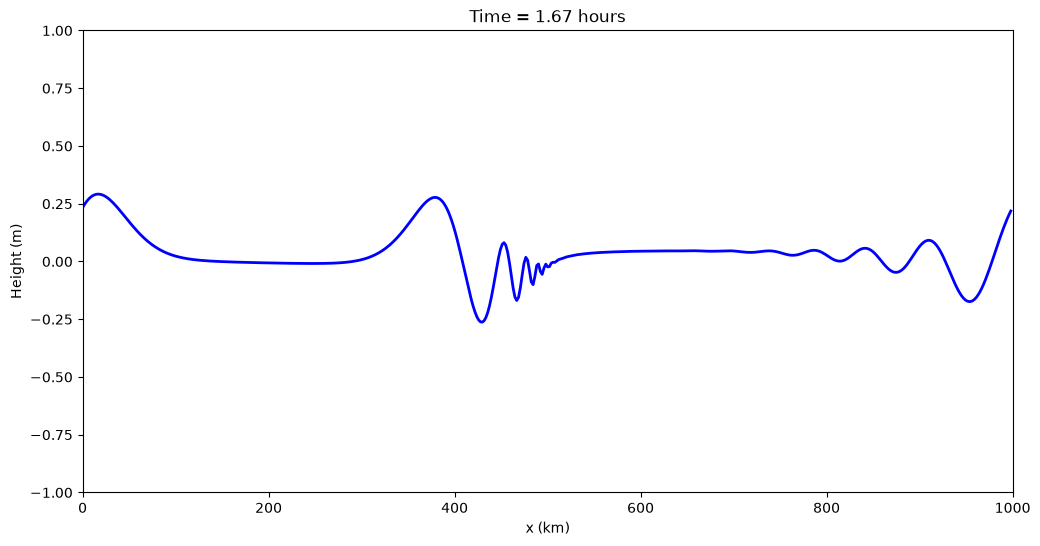

In [2]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Specify the axis limits and labels
plt.xlim((0, Lx / (1*kilometer)))            
plt.ylim((-1, 1))
plt.xlabel('x (km)')
plt.ylabel('Height (m)')

# Create objects that will change during the animation
txt_title = plt.title('')
height, = plt.plot([], [], 'b', lw=2)    

# Define an animation function
def drawframe(n):
    height.set_data(x/(1*kilometer), h_save[n,:])
    txt_title.set_text('Time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'

import matplotlib.animation as animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())


### 1.3 Student investigation
<a id='section1pt3'></a>
In the cells below, provide an expression for the expected wave speed and state any assumptions that are necessary to arrive at this. Then plot the wave speed from the output above and compare this with the expected value. 

If you assume that u and h are small, you can neglect any terms that are products of u and h.
This means you can rewrite the momentum equations as

$ \frac{\partial^2 h}{\partial t^2} = g \left(\frac{\partial H}{\partial x}\frac{\partial h}{\partial x}+ H\frac{\partial^2 h}{\partial x^2}\right) $.

Because H varies over a much larger lengthscale than h, $\frac{\partial H}{\partial x}$ is much smaller than $\frac{\partial h}{\partial x}$. So neglect the term involving $\frac{\partial H}{\partial x}$ and approximate the equation as:

$ \frac{\partial^2 h}{\partial t^2} = g H\frac{\partial^2 h}{\partial x^2}$.

If we compare this to the 1D wave eqn $\psi_{tt}=c^2\psi_{xx}$, we can say that $c^2 = gH$.

In otherwords, wave speed $c = \sqrt{gH}$.

Text(250, 350, 'Final time = 0.98 hrs')

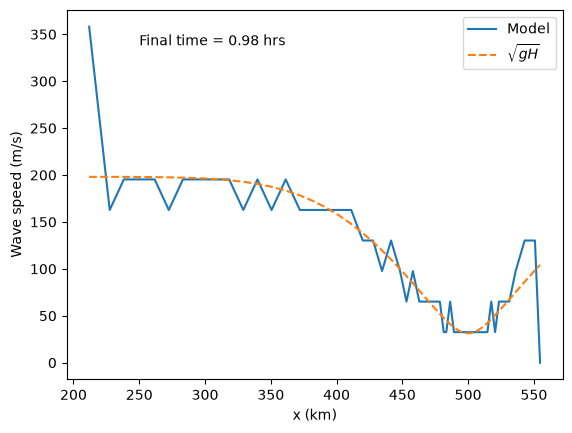

In [ ]:
t_trim = t_save[1:60]
h_save_trim = h_save[1:60,:]

ix_max_trim = np.array([np.argmax(np.where(x > x1, hs, -np.inf)) for hs in h_save_trim])
x_val_trim = x[ix_max_trim]

dxdt_trim = np.diff(x_val_trim) / np.diff(t_trim)

ix_max = np.array([np.argmax(np.where(x > x1, hs, -np.inf)) for hs in h_save])
x_val = x[ix_max]

dxdt = np.diff(x_val) / np.diff(t_save)


#####Using the midpoint for both curves means the measured and predicted speeds refer to the same location:
#####Each measured speed is at the centre of the interval it averaged over, and the prediction is evaluated at those same x values ---> compare like with like.

x_mid_trim = 0.5 * (x_val_trim[1:] + x_val_trim[:-1])
H_mid_trim = H0 - (H0 - H_min) * np.exp(-(x_mid_trim - x2)**2 / w2**2)

x_mid = 0.5 * (x_val[1:] + x_val[:-1])
H_mid = H0 - (H0 - H_min) * np.exp(-(x_mid - x2)**2 / w2**2)

speed_pred_trim = np.sqrt(g * H_mid_trim)
speed_pred = np.sqrt(g * H_mid)


plt.plot(x_mid_trim/kilometer, dxdt_trim, label='Model')
plt.plot(x_mid_trim/kilometer, speed_pred_trim, '--', label=r'$\sqrt{gH}$')
plt.legend()
plt.xlabel('x (km)'); plt.ylabel('Wave speed (m/s)')
plt.text(250, 350,f'Final time = {t_trim[-1] / hour:.2g} hrs',va='top')

#plt.plot(x_mid/kilometer, dxdt, label='Model')
#plt.plot(x_mid/kilometer, speed_pred, '--', label=r'$\sqrt{gH}$')
#plt.legend()
#plt.xlabel('x (km)'); plt.ylabel('Wave speed (m/s)')
#plt.text(250, 350,f'Final time = {t_save[-1] / hour:.2g} hrs',va='top')




The analytical solution for wavespeed and the numerical output seem to agree. This suggests the assumptions we made when coming up with the analytical solution were valid (h,u small, dH/dx small). We see the speed is constant for x far away from the seamount, $c \approx 200 ms^{-1} = \sqrt{10 \times 4e3}$ which corresponds with the solution for a flat bottom of $H=H_0=4km$. As the wave gets closer to the seamount, it slows down which corresponds to the water becoming more shallow as $H \rightarrow H_{min}$. The model wave speed is quite rough, which I think is probably due to the timestep and grid spacing being too large to produce a smooth dx/dt. The reason I am only looking at the first hour of the simulation is that for later times, the periodic fourier grid means we get the wave that travelled to the left from the initial position coming back into the grid on the right, causing the results to deviate from the model as they include extra waves that are not physically relevant. 

## 2.  2D Shallow water equations

Now, let's see how things change if we move to two dimensions. The script below solves the 2D shallow water equations:

$$ \partial_t u + g \partial_x(h) = - u*\partial_x u - v*\partial_y u$$
$$ \partial_t u + g \partial_y(h) = - u*\partial_x v - v*\partial_y v$$
$$ \partial_t h + H (\partial_x(u) + \partial_y(v)) = -\partial_x(h*u) - \partial_y(h*v)$$

We will solve these equations in a square domain with periodic boundary conditions. We will again initialize with a Gaussian height disturbance and with no water motion, but this time in 2D:

$$ h=e^{-(x^2+y^2)/w^2} $$
$$ u=0 $$
$$ v=0 $$

### 2.1  Dedalus script to solve the 2D shallow water equations

In [8]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Specify the simulation parameters
Lx = 1000 * kilometer # The domain size in x
Ly = 1000 * kilometer # The domain size in y
Nx = 64 # The number of gridpoints in x
Ny = 64 # The number of gridpoints in y
g = 9.81 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Reference ocean depth
widthx = 10 * kilometer # Set the width of the initial Gaussian
widthy = 100 * kilometer
width = 100 * kilometer
r = np.sqrt(x**2 + y**2)

timestep = 60 * second # Specify the timestep
stop_sim_time = 30 * minute # Specify the stopping time

timestepper = dedalus.RK222
max_timestep = 0.125

# Bases
coords = dedalus.CartesianCoordinates('x', 'y')
dist = dedalus.Distributor(coords, dtype=np.float64)
xbasis = dedalus.RealFourier(coords['x'], size=Nx, bounds=(-Lx/2, Lx/2), dealias=3/2)
ybasis = dedalus.RealFourier(coords['y'], size=Ny, bounds=(-Ly/2, Ly/2), dealias=3/2)

x, y = dist.local_grids(xbasis, ybasis)

# Fields
u = dist.Field(name='u', bases=(xbasis, ybasis))
v = dist.Field(name='v', bases=(xbasis, ybasis))
h = dist.Field(name='h', bases=(xbasis, ybasis))

# Initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
v.change_scales(1)
h['g'] = r <= width #
#h['g'] = np.exp(-(x**2)/widthx**2-(y**2)/widthy**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
u['g'] = 0
v['g'] = 0

# Operators
dx = lambda a: dedalus.Differentiate(a, coords['x'])
dy = lambda a: dedalus.Differentiate(a, coords['y'])

# Problem
problem = dedalus.IVP([u, v, h], namespace=locals())
problem.add_equation("dt(u) + g*dx(h) = - u*dx(u) - v*dy(u)")
problem.add_equation("dt(v) + g*dy(h) = - u*dx(v) - v*dy(v)")
problem.add_equation("dt(h) + H*(dx(u) + dy(v)) = - dx(h*u) - dy(h*v)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Analysis
snapshots = solver.evaluator.add_file_handler('snapshots', sim_dt=1*hour, max_writes=10)
snapshots.add_task(h, name='h')
snapshots.add_task(u, name='u')
snapshots.add_task(v, name='v')

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_8=np.array(h_save) # convert h_save to an np.array type to allow data slicing

2026-11-21 19:56:09,856 subsystems 0/1 INFO :: Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 0s, Rate: 6.9e+01/s
2026-11-21 19:56:09,894 subsystems 0/1 INFO :: Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 0s, Rate: 7.6e+01/s
2026-11-21 19:56:09,940 subsystems 0/1 INFO :: Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 8.1e+01/s
2026-11-21 19:56:09,981 subsystems 0/1 INFO :: Building subproblem matrices 12/32 (~38%) Elapsed: 0s, Remaining: 0s, Rate: 8.6e+01/s
2026-11-21 19:56:10,020 subsystems 0/1 INFO :: Building subproblem matrices 16/32 (~50%) Elapsed: 0s, Remaining: 0s, Rate: 9.0e+01/s
2026-11-21 19:56:10,061 subsystems 0/1 INFO :: Building subproblem matrices 20/32 (~62%) Elapsed: 0s, Remaining: 0s, Rate: 9.1e+01/s
2026-11-21 19:56:10,097 subsystems 0/1 INFO :: Building subproblem matrices 24/32 (~75%) Elapsed: 0s, Remaining: 0s, Rate: 9.4e+01/s
2026-11-21 19:56:10,138 subsystems 0/1 INFO :: Building subproblem matric

### 2.2  Plotting
The code below will make a movie of the height as a function of x and y

2026-11-15 13:49:30,387 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-15 13:49:30,388 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp3xc4ct0h/temp.m4v


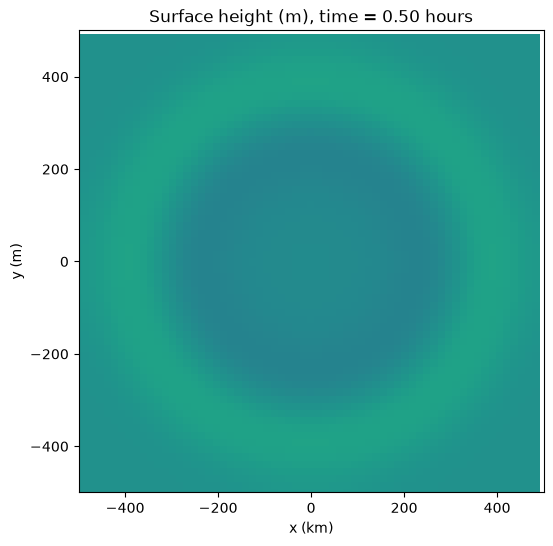

In [ ]:
# create a figure and axes
fig = plt.figure(figsize=(6,6))

# Create arrays with the x and y coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(x), np.squeeze(y)) 

# Define an animation function
def drawframe(n):
    plt.clf # clear the figure before plotting the next frame
    height = plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h_save[n,:,:], vmin=-1, vmax=1)
    # Specify the axis limits and labels
    plt.xlim((-Lx/2 / (1*kilometer),Lx/2 / (1*kilometer)))   
    plt.ylim((-Ly/2 / (1*kilometer),Ly/2 / (1*kilometer)))            
    plt.xlabel('x (km)')
    plt.ylabel('y (m)')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'

import matplotlib.animation as animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 2.3 Student investigation
<a id='section2pt3'></a>
Notice how the amplitude of the Tsunami wave decreases with distance from the source location. In the cell below, make a prediction for how the wave amplitude will vary as a function of distance from the origin (x=0, y=0) using conservation of energy. Then, make a plot or plots comparing your prediction for the wave amplitude compared with the results from the simulation. 

Try out several different possible initial conditions for the surface height, $h$. How does the shape of the resulting waves change?

**Amplitude Predictions**

Because the waves are non-dispersive, we can assume that the width of the annulus is a constant, $\Delta$. So the area of the annulus is $2\pi r \Delta$.

From the linearised momentum equations above, we have $u, v \sim h$. So we can say that $(u^2+v^2) \sim h^2$.

We have a flat bottom at $z = h_b = - H_0$ with $h$ a small perturbation about $z=0$. The total fluid height is $H = h+ H_0$

Kinetic Energy density (K) is $\frac{1}{2}\rho(u^2 + v^2)(h+H_0)$. Since $h<<H_0$, we can say that kinetic energy density $\sim \rho h^2 H_0$.

Potential Energy density (P) is $\frac{1}{2}\rho g (h^2+H_0^2)$. Because $H_0$ is a constant background height that doesn't change the physics (assume the rest state has zero relative potential energy to balance zero kinetic energy) we can ignore it.

So $P + K \sim (const) h^2)$ and hence $r h^2 \sim 1$ or $h \sim \frac{1}{\sqrt{r}}$.

So as the distance of the wave from the source doubles, height should decrease by a factor of $\frac{1}{\sqrt{2}}$. 

For initial Amplitude 1km, maximum height at y = 203.12km was 0.21km. At y = 390.62km h was 0.16km. Given we have approximately doubled y, we would expect a height of 0.15km.
For initial Amplitude 2km, maximum height at y = 203.12km was 0.43km. At y = 390.62km h was 0.31km. Given we have approximately doubled y, we would expect a height of 0.30km.
For initial Amplitude 0.5km, maximum height at y = 203.12km was 0.11km. At y = 390.62km h was 0.08km. Given we have approximately doubled y, we would expect a height of 0.08km.


Text(0.5, 0.98, 'Cylinder with width 100km')

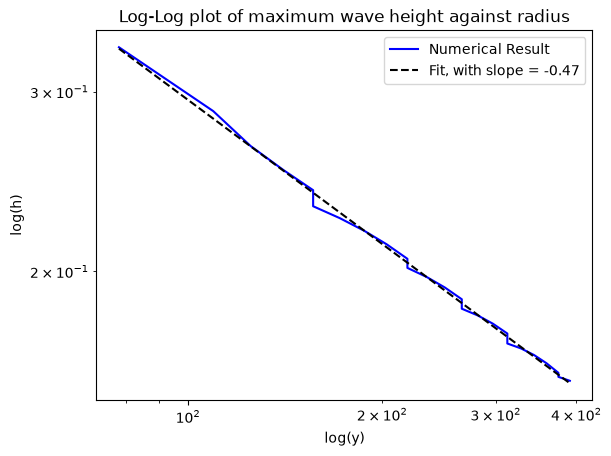

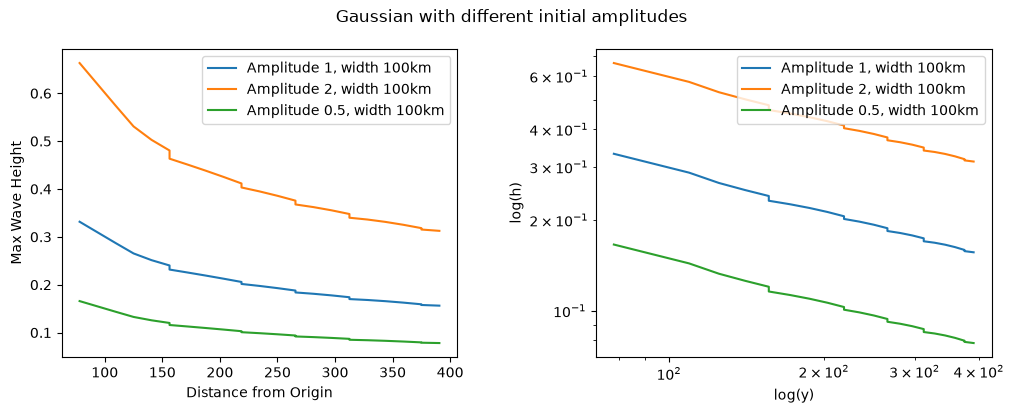

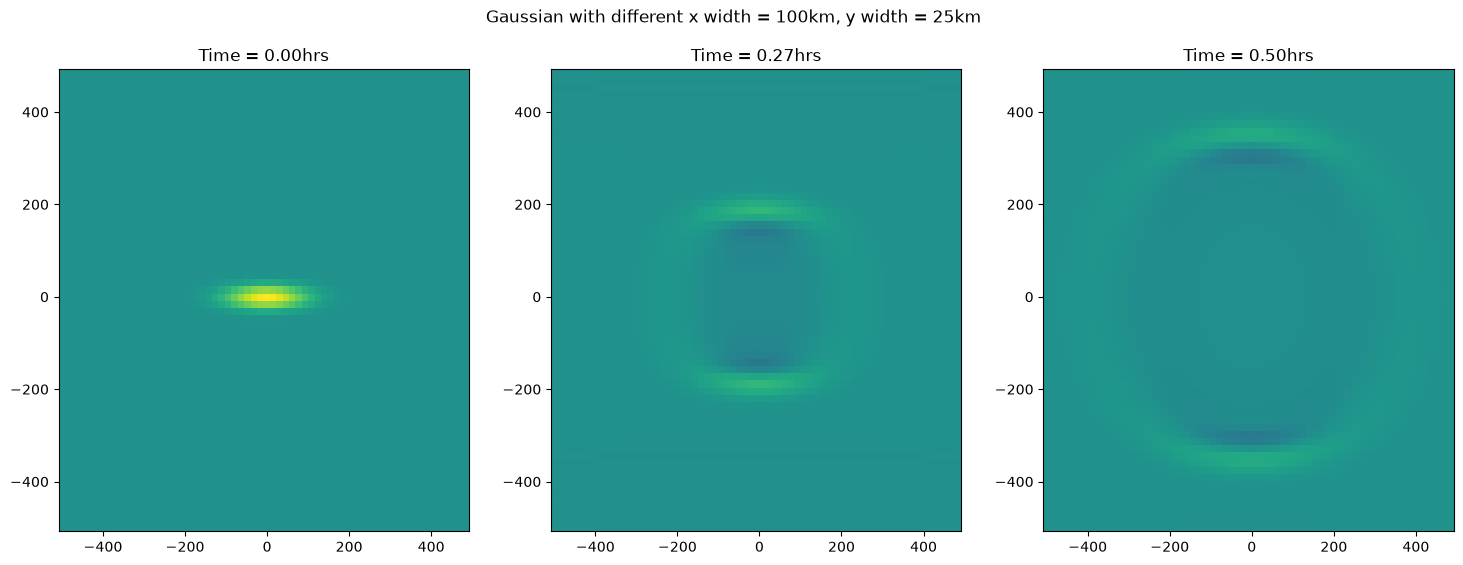

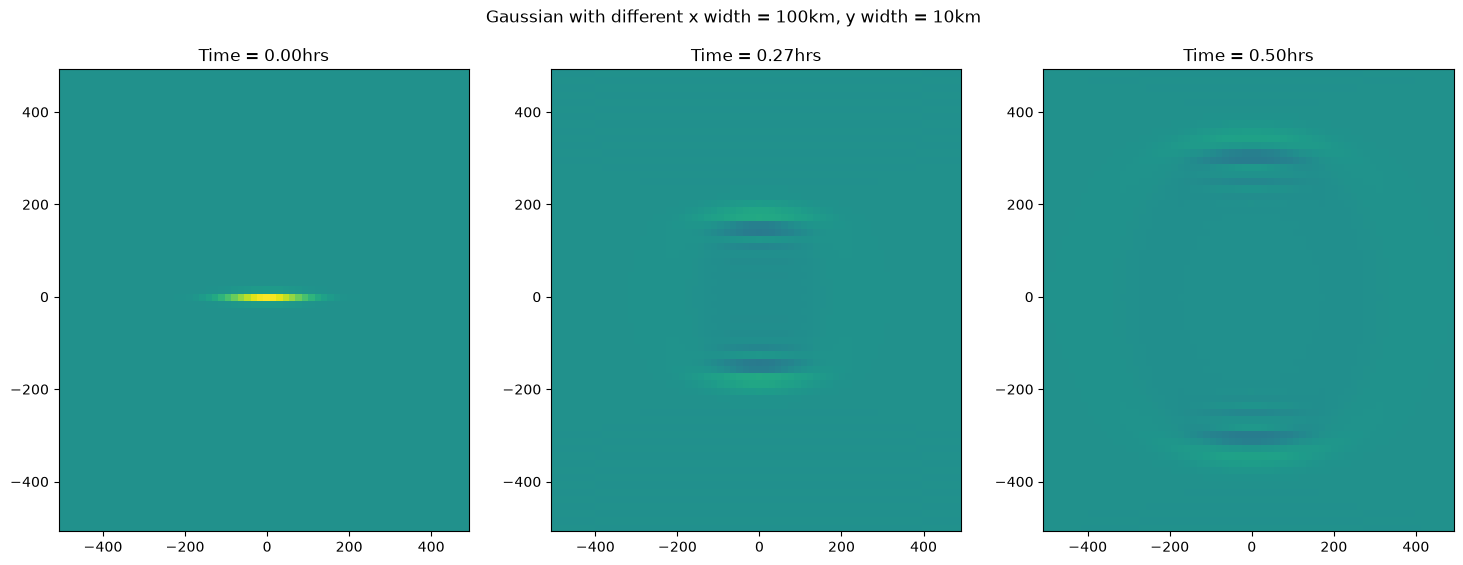

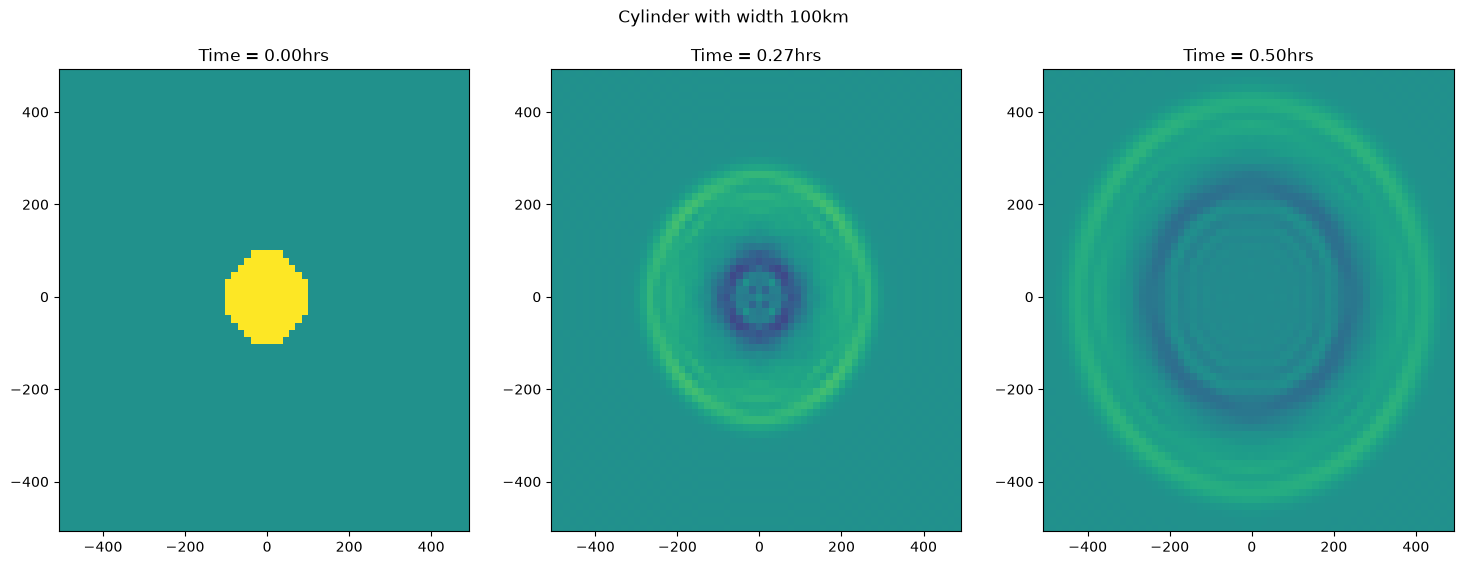

In [14]:
### AMPLITUDE INVESTIGATIONS ######

ix = 32   
iy = 32   

hquad = [h[:, ix, iy:] for h in (h_1, h_2, h_3)]   

iy_max = [np.argmax(hq, axis=1) for hq in hquad]      
h_max  = [hq.max(axis=1) for hq in hquad]             
y_val  = [y[0, iy + im] for im in iy_max]            

h_max1, h_max2, h_max3 = h_max
y_val1, y_val2, y_val3 = y_val

trim_val = 6 #6


y_val1 = y_val1[trim_val:]; h_max1 = h_max1[trim_val:]
y_val2 = y_val2[trim_val:]; h_max2 = h_max2[trim_val:]
y_val3 = y_val3[trim_val:]; h_max3 = h_max3[trim_val:]


pred1 = h_max1[8]/np.sqrt(2)
pred2 = h_max2[8]/np.sqrt(2)
pred3 = h_max3[8]/np.sqrt(2)
print(f'For initial Amplitude 1km, maximum height at y = {y_val1[8]/kilometer:.2f}km was {h_max1[8]:.2f}km. At y = {y_val1[-1]/kilometer:.2f}km h was {h_max1[-1]:.2f}km. Given we have approximately doubled y, we would expect a height of {pred1:.2f}km.')
print(f'For initial Amplitude 2km, maximum height at y = {y_val2[8]/kilometer:.2f}km was {h_max2[8]:.2f}km. At y = {y_val2[-1]/kilometer:.2f}km h was {h_max2[-1]:.2f}km. Given we have approximately doubled y, we would expect a height of {pred2:.2f}km.')
print(f'For initial Amplitude 0.5km, maximum height at y = {y_val3[8]/kilometer:.2f}km was {h_max3[8]:.2f}km. At y = {y_val3[-1]/kilometer:.2f}km h was {h_max3[-1]:.2f}km. Given we have approximately doubled y, we would expect a height of {pred3:.2f}km.')

logy = np.log(y_val1)
logh = np.log(h_max1)

slope, intercept = np.polyfit(logy, logh, 1)


h_fit = np.exp(intercept) * y_val1**slope

#########################
### TESTING 1/Y^2 FIT####
#########################
plt.figure()
plt.loglog(y_val1/kilometer, h_max1, 'b-', label='Numerical Result')
plt.loglog(y_val1/kilometer, h_fit, 'k--', label=f'Fit, with slope = {slope:.2f}')
plt.xlabel('log(y)'); plt.ylabel('log(h)')
plt.legend()
plt.title('Log-Log plot of maximum wave height against radius')


#########################
### VARYING AMPLITUDE ###
#########################

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(y_val1/kilometer, h_max1,  label = 'Amplitude 1, width 100km')
plt.plot(y_val2/kilometer, h_max2, label = 'Amplitude 2, width 100km')
plt.plot(y_val3/kilometer, h_max3, label = 'Amplitude 0.5, width 100km')
plt.ylabel('Max Wave Height')
plt.xlabel('Distance from Origin')
plt.legend()


plt.subplot(1,2,2)
plt.loglog(y_val1/kilometer, h_max1,  label = 'Amplitude 1, width 100km')
plt.loglog(y_val2/kilometer, h_max2, label = 'Amplitude 2, width 100km')
plt.loglog(y_val3/kilometer, h_max3, label = 'Amplitude 0.5, width 100km')
plt.ylabel('log(h)')
plt.xlabel('log(y)')
plt.legend()

plt.subplots_adjust(wspace=0.35)
plt.suptitle('Gaussian with different initial amplitudes')




#########################
### Other Wave Shapes ###
#########################

from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(x), np.squeeze(y)) 

tarr = np.array(t_save)/(1*hour)
times = [tarr[0], tarr[16], tarr[-1]]

h6 = [h_6[0,:,:], h_6[16,:,:], h_6[-1,:,:]]
h7 = [h_7[0,:,:], h_7[16,:,:], h_7[-1,:,:]]
h8 = [h_8[0,:,:], h_8[16,:,:], h_8[-1,:,:]]



### y = 0.25x ###

fig = plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h6[0], vmin=-1, vmax=1)
plt.title(f'Time = {times[0]:.2f}hrs')

plt.subplot(1,3,2)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h6[1], vmin=-1, vmax=1)
plt.title(f'Time = {times[1]:.2f}hrs')

plt.subplot(1,3,3)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h6[2], vmin=-1, vmax=1)
plt.title(f'Time = {times[2]:.2f}hrs')

plt.subplots_adjust(wspace=0.2)
plt.suptitle('Gaussian with different x width = 100km, y width = 25km')


### y = 0.1x ###

fig = plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h7[0], vmin=-1, vmax=1)
plt.title(f'Time = {times[0]:.2f}hrs')

plt.subplot(1,3,2)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h7[1], vmin=-1, vmax=1)
plt.title(f'Time = {times[1]:.2f}hrs')

plt.subplot(1,3,3)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h7[2], vmin=-1, vmax=1)
plt.title(f'Time = {times[2]:.2f}hrs')

plt.subplots_adjust(wspace=0.2)
plt.suptitle('Gaussian with different x width = 100km, y width = 10km')


### cylinder ###

fig = plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h8[0], vmin=-1, vmax=1)
plt.title(f'Time = {times[0]:.2f}hrs')

plt.subplot(1,3,2)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h8[1], vmin=-1, vmax=1)
plt.title(f'Time = {times[1]:.2f}hrs')

plt.subplot(1,3,3)
plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h8[2], vmin=-1, vmax=1)
plt.title(f'Time = {times[2]:.2f}hrs')

plt.subplots_adjust(wspace=0.2)
plt.suptitle('Cylinder with width 100km')


 

**Varying Amplitude**
- For initial Amplitude 1m, maximum height at y = 203.12km was 0.21m. At y = 390.62km h was 0.16m. Given we have approximately doubled y, we would expect a height of 0.15m, which is very close to what we saw.
- For initial Amplitude 2m, maximum height at y = 203.12km was 0.43m. At y = 390.62km h was 0.31m. Given we have approximately doubled y, we would expect a height of 0.30m, which is very close to what we saw.
- For initial Amplitude 0.5m, maximum height at y = 203.12km was 0.11m. At y = 390.62km h was 0.08m. Given we have approximately doubled y, we would expect a height of 0.08m, which is waht we saw.
- All amplitudes give us $h \sim 1/\sqrt{r}$, same shape wave

**Varying xy ratio**
- When the intial gaussian is stretched so that it is wider in x than in y, we see that the height of the wave in the y direction is greater.
- The more stretched the initial gaussian is in the x direction, the less the initial height anomoly propogates in the x direction, relative to the y direction.
- This sort of intuitively makes sense as you would expect, if the initial gaussian was stretched infinitely in either direction, the equations would effectively become 1d, with two plane waves propogating in the positive and negative y direction.

**Cylinder not Gaussian**
- When we start with a cylinder, not a gaussian, we see lots of rings of waves.
- We are still considering the shallow water equations, so expect the wavefront to travel at the same speed as in the gaussian case $(\sqrt{gH})$.
- W also expect the amplitude to fall off as $1/\sqrt{r}$.
- From a visual inspection of the plots compared with the original gaussian wave, the main wavefront does seem to have travelled the same distance in both cases.
- The extra rings in the cylinder case is probably because the initial wave was a step function, or it could be due to the fourier basis in dedalus having trouble decomposing it into constituent exponential functions.
- Further investigations could try the same thing with different shaped step functions.

## 3. Shallow water equations on a sphere

Of course the Earth isn't a flat plane. A great strength of Dedalus is its flexibility to solve equations in various geometries. The script below solves the 2D shallow water equations on a spherical shell, where the azimuth and colatitude are the independent variables. The colatitude is the complementary angle to the latitude such that the colatitude is $0^\circ$ at the North Pole, $90^\circ$ at the Equator, and $180^\circ$ at the South Pole. The spherical geometry also allows us to take into account the Earth's rotation in a realistic way. 

Specifically, we will solve the following equations:
$$ \partial_t \mathbf{u} + g \nabla h + 2 \Omega \hat{\mathbf{z}} \times \mathbf{u} = -\mathbf{u} \cdot \nabla \mathbf{u} $$
$$ \partial_t + H \nabla \cdot \mathbf{u} = -\nabla \cdot (h \mathbf{u}) $$

where $\mathbf{u}$ is the velocity vector, $\Omega$ is the Earth's angular velocity (in radians per second), and $\hat{\mathbf{z}}$ is a unit vector aligned with the North Pole. Note that we have written the equations above in vector form. Dedalus includes vector calculus operators that make it very natural to solve equations like this without worrying about the particular form of the vector operators in a curvilinear coordinate system.

### 3.1  Dedalus script for 2D shallow water equations on a sphere

In [1]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.37122e3 * kilometer
Omega = 2 * np.pi / (1 * day) # Earth's angular velocity in radians per second
g = 9.80616 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Depth of the ocean
width = 2*np.pi*10/360 # Width of the initial Gaussian in radians
phi0 = np.pi # Longitude of the initial Gaussian height perturbation in radians
theta0 = np.pi/4 # Colatitude of the initial Gaussian height perturbation in radians

timestep = 600 * second
stop_sim_time = 10 * day

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis) # Longitude and colatitude
lat = 360*(np.pi / 2 - theta)/(2*np.pi)  # latitude in degrees

# Fields
u = dist.VectorField(coords, name='u', bases=basis)
h = dist.Field(name='h', bases=basis)

# Operators
# First, create an operator to perform the cross product: "z x ", where z is the local vertical unit vector
# The "skew" operator performs a 90 degree rotation of a vector field,
# so that skew([u,v]) = [-v, u].  MulCosine multiplies by the cosine of the latitude
zcross = lambda A: dedalus.MulCosine(dedalus.skew(A))

# Set the initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
h['g'] = np.exp(-((phi-phi0)**2+(theta-theta0)**2)/width**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
# Set the initial velocity to zero
u['g'][0] = 0 # the x-component of the velocity
u['g'][1] = 0 # the y-component of the velocity

# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*grad(h) + 2*Omega*zcross(u) = - u@grad(u)")
problem.add_equation("dt(h) + H*div(u) = - div(h*u)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save = np.array(h_save)

2026-11-19 16:10:01,204 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 4s, Rate: 1.7e+01/s
2026-11-19 16:10:01,299 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 4.5e+01/s
2026-11-19 16:10:01,405 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 5.4e+01/s
2026-11-19 16:10:01,533 subsystems 0/1 INFO :: Building subproblem matrices 21/63 (~33%) Elapsed: 0s, Remaining: 1s, Rate: 5.4e+01/s
2026-11-19 16:10:01,643 subsystems 0/1 INFO :: Building subproblem matrices 28/63 (~44%) Elapsed: 1s, Remaining: 1s, Rate: 5.6e+01/s
2026-11-19 16:10:01,810 subsystems 0/1 INFO :: Building subproblem matrices 35/63 (~56%) Elapsed: 1s, Remaining: 1s, Rate: 5.3e+01/s
2026-11-19 16:10:01,945 subsystems 0/1 INFO :: Building subproblem matrices 42/63 (~67%) Elapsed: 1s, Remaining: 0s, Rate: 5.2e+01/s
2026-11-19 16:10:02,066 subsystems 0/1 INFO :: Building subproblem matri

### 3.2  Plotting
The code below will make a movie of the height as a function of x and y

2026-11-15 13:51:52,392 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-15 13:51:52,393 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmprs3zjkja/temp.m4v


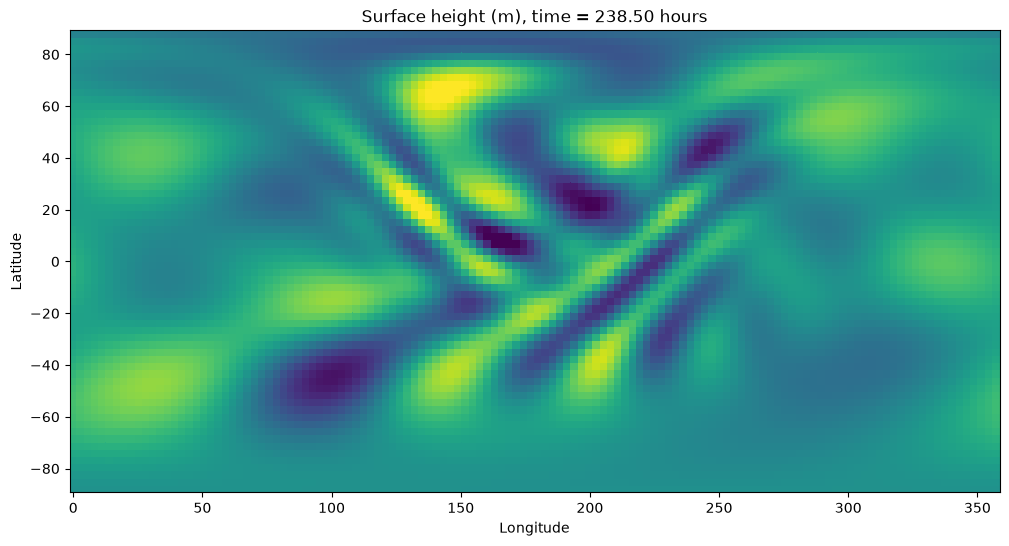

In [ ]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(np.pi/2 - theta)*360/2/np.pi, np.squeeze(phi)*360/2/np.pi)  

# Define an animation function
def drawframe(n):
    plt.clf()
    height = plt.pcolor(Y, X, h_save[n,:,:], vmin=-0.1, vmax=0.1)
    # Specify the axis limits and labels         
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 3.3 Student investigation
<a id='section3pt3'></a>
Create a virtual tide gauge by sampling the height at a point at a latitude of 45ºN and longitude of 90ºW and plot the timeseries of the height at this point in the cells below. You should modifty the code to save the height more often so that you can clearly see the shape of the wave. Notice that as the waves propagate around the Earth, their shape changes. Discuss physical mechanisms that might cause the shape of the wave to change as the wave propagates.

(1441, 128, 64) (128,) (64,) (64,)
Phi and Theta idices: 96, 48
Do my lattitude and colatitude add up to 90 degrees: True
['46.04$^\\circ$N', '90.00$^\\circ$W']


Text(0.5, 1.0, 'Tide gauge for 46.04$^\\circ$N 90.00$^\\circ$W')

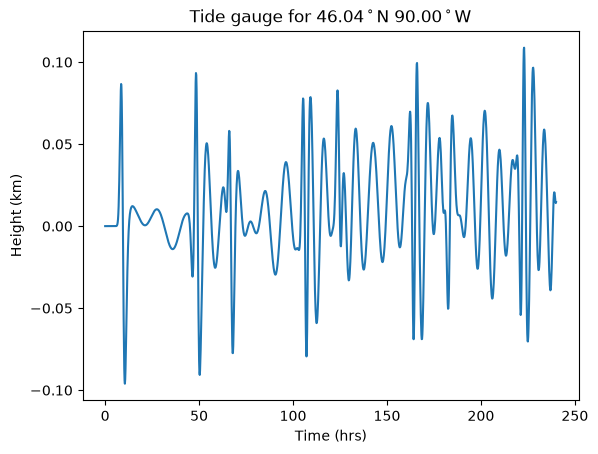

In [69]:
phi1d   = phi[:, 0]            # (longitude,)   radians
theta1d = theta[0, :]          # (colatitude,) radians
lat1d   = 90 - np.degrees(theta1d)   # (latitude,) radians

print(h_save.shape, phi1d.shape, theta1d.shape, lat1d.shape)

iphi = np.argmin(np.abs(np.degrees(phi1d) - 270))
itheta = np.argmin(np.abs(lat1d - 45))

print(f'Phi and Theta idices: {iphi}, {itheta}')

true_colat = theta1d[itheta] #radians
true_lat = lat1d[itheta] #degrees
true_long = phi1d[iphi] #radians

print('Do my lattitude and colatitude add up to 90 degrees: {}'.format(not(bool(true_lat + np.degrees(true_colat) - 90))))

fancy_lat_long = ['','']
if true_lat < 0:
    fancy_lat_long[0] = rf'{abs(true_lat):.2f}$^\circ$S'
else: fancy_lat_long[0] = rf'{true_lat:.2f}$^\circ$N'

if (np.degrees(true_long) -180) < 0:
    fancy_lat_long[1] = rf'{np.degrees(true_long):.2f}$^\circ$E'
else: fancy_lat_long[1] = rf'{np.degrees(true_long) - 180:.2f}$^\circ$W'

print(fancy_lat_long)

height = h_save[:,iphi,itheta]
time = np.array(t_save)/(1*hour)

plt.plot(time,height)
plt.xlabel('Time (hrs)')
plt.ylabel('Height (km)')
plt.title(f'Tide gauge for {fancy_lat_long[0]} {fancy_lat_long[1]}')


In [3]:
lat = 45
f0 = 2*2*np.pi*np.sin(lat)/(60*60*24)
k = 1/(R*np.cos(lat)*width)
l = 1/(R*width)
omega = np.sqrt(f0**2 +g*H*(k**2+l**2))
cgx = g*H*k/omega
dist = 79*kilometer*90

tx = dist/cgx
print(tx/hour)

11.837906824938493


The source wave starts at 45N 180E.
The shallow water gravity waves for a rotating sphere have group velocity:
$$ C_g = \frac{gH}{\omega}(k,l)$$
where 
$$ \omega^2 = f_0^2 + gH(k^2 + l^2)$$
We would expect the initial wave to reach our tide gauge approximately 12hrs after the start of the simulation.
You can clearly see the initial crest and trough of the wave passing about 10hrs after the start, which corresponds to this speed. I think the rest of the shapes come in due to constructive and destructive interference of the wavefront with itself as it reenters the domain through the periodic boundary. We also have the effects of rotation varying with latitude accross the sphere, so the parts of the wavefront that initially head towards the equator will feel less of the rotation than those which initially head polewards. So when you combine all these waves that are travelling in different directions, and accellerating in different directions, once they start to interact after 30hrs, you get all sorts of shapes.

In the simulation above, the Tsunami wave travels around the planet many times. In reality, the waves will partially dissipate when they reach shorelines. In the spherical shallow water equation code above (or in a new code block below), add a forcing term to the shallow water equations that damps the waves for longitudes larger than $\pm 90^\circ$. Specifically, add a forcing function to the right hand side of the height equation of the following form:

$$ - (1/\tau) f(\phi) h$$

where

$$ f(\phi) = \frac{1}{2}\left(1+tanh\left(\frac{\phi-3\pi/2}{\pi/10}\right)\right) + \frac{1}{2}\left(1-tanh\left(\frac{\phi-\pi/2}{\pi/10}\right)\right) $$

and $\phi$ is the co-latitude in radians and $\tau$ is a damping timescale. A timescale of $\tau=0.1$ days should be sufficient to damp the waves.

With this damping term active, much more slowly propagating waves should be visible. These are shallow water Rossby waves. Estimate the east/west phase speed of these Rossby waves and compare them with the phase speed that you can infer from the simulation by plotting the height, $h$, as a function of longitude and time. Discuss the spatial structure of the Rossby waves and any discrepancies that you see between your estimated and measured phase speeds.

In [15]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.37122e3 * kilometer
Omega = 2 * np.pi / (1 * day) # Earth's angular velocity in radians per second
g = 9.80616 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Depth of the ocean
width = 2*np.pi*10/360 # Width of the initial Gaussian in radians
phi0 = np.pi # Longitude of the initial Gaussian height perturbation in radians
theta0 = np.pi/4 # Colatitude of the initial Gaussian height perturbation in radians
tau = 0.1*day

timestep = 600 * second
stop_sim_time = 10 * day

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis) # Longitude and colatitude
lat = 360*(np.pi / 2 - theta)/(2*np.pi)  # latitude in degrees

# Fields
u = dist.VectorField(coords, name='u', bases=basis)
h = dist.Field(name='h', bases=basis)

# Operators
# First, create an operator to perform the cross product: "z x ", where z is the local vertical unit vector
# The "skew" operator performs a 90 degree rotation of a vector field,
# so that skew([u,v]) = [-v, u].  MulCosine multiplies by the cosine of the latitude
zcross = lambda A: dedalus.MulCosine(dedalus.skew(A))

# Set the initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
h['g'] = np.exp(-((phi-phi0)**2+(theta-theta0)**2)/width**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
# Set the initial velocity to zero
u['g'][0] = 0 # the x-component of the velocity
u['g'][1] = 0 # the y-component of the velocity

f = dist.Field(name='f', bases=basis)
f['g'] = 0.5*(1+np.tanh((phi-(3*np.pi/2))/(np.pi/10))) + 0.5*(1 - np.tanh((phi - np.pi/2)/(np.pi/10)))
# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*grad(h) + 2*Omega*zcross(u) = - u@grad(u)")
problem.add_equation("dt(h) + H*div(u) = - div(h*u) - (1/tau)*f*h")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
f.change_scales(1)
f_save = [np.copy(f['g'])]; 
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save = np.array(h_save)

2026-11-21 20:32:52,629 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 22s, Rate: 2.8e+00/s
2026-11-21 20:32:52,949 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 1s, Remaining: 6s, Rate: 1.0e+01/s
2026-11-21 20:32:53,081 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 1s, Remaining: 3s, Rate: 1.7e+01/s
2026-11-21 20:32:53,207 subsystems 0/1 INFO :: Building subproblem matrices 21/63 (~33%) Elapsed: 1s, Remaining: 2s, Rate: 2.2e+01/s
2026-11-21 20:32:53,530 subsystems 0/1 INFO :: Building subproblem matrices 28/63 (~44%) Elapsed: 1s, Remaining: 2s, Rate: 2.2e+01/s
2026-11-21 20:32:53,659 subsystems 0/1 INFO :: Building subproblem matrices 35/63 (~56%) Elapsed: 1s, Remaining: 1s, Rate: 2.5e+01/s
2026-11-21 20:32:53,782 subsystems 0/1 INFO :: Building subproblem matrices 42/63 (~67%) Elapsed: 2s, Remaining: 1s, Rate: 2.7e+01/s
2026-11-21 20:32:53,900 subsystems 0/1 INFO :: Building subproblem matr

(128, 1) (1, 64) (1, 128, 64)


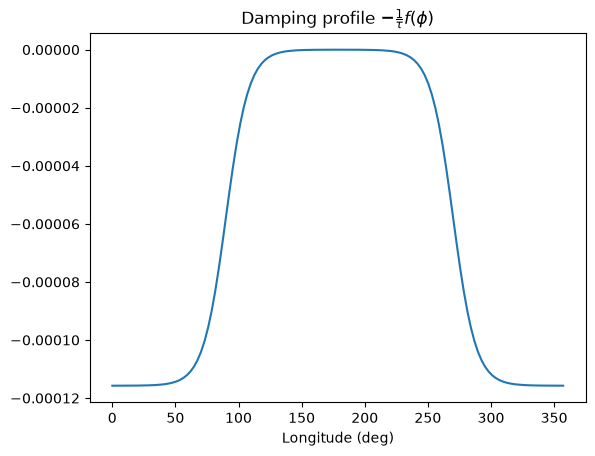

2026-11-19 11:08:41,718 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-19 11:08:41,760 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmphfunk6q6/temp.m4v


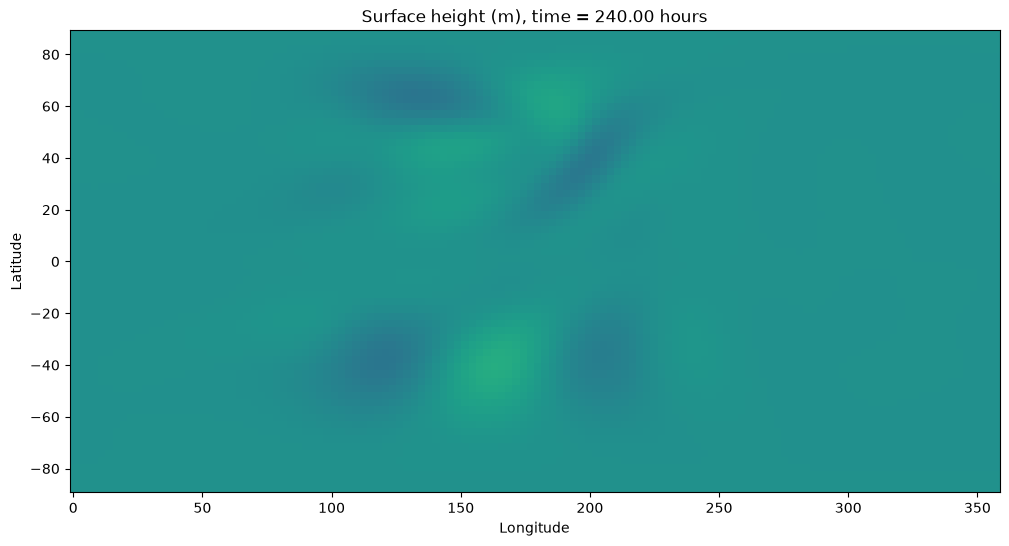

In [33]:
f_save = np.array(f_save)
print(phi.shape, theta.shape, f_save.shape)
lon_deg = np.degrees(phi[:, 0])


plt.plot(lon_deg, -(1/tau)*f_save[0,:, 0])
plt.xlabel('Longitude (deg)')
plt.title(r'Damping profile $-\frac{1}{\tau}f(\phi)$')
plt.show()


# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(np.pi/2 - theta)*360/2/np.pi, np.squeeze(phi)*360/2/np.pi)  

# Define an animation function
def drawframe(n):
    plt.clf()
    height = plt.pcolor(Y, X, h_save[n,:,:], vmin=-0.1, vmax=0.1)
    # Specify the axis limits and labels         
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())


2026-11-19 11:46:03,860 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-19 11:46:03,862 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 800x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpfmpmpox7/temp.m4v


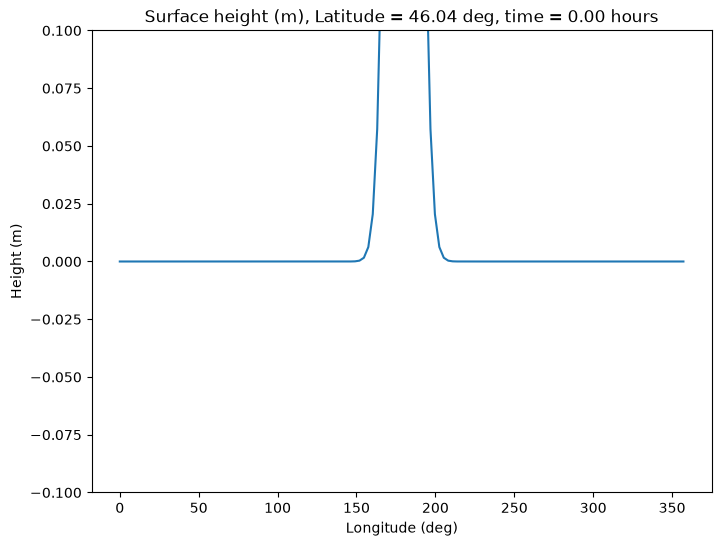

In [ ]:
phi1d   = phi[:, 0]                    # (longitude,) radians
theta1d = theta[0, :]                  # (colatitude,) radians
lat1d   = 90 - np.degrees(theta1d)     # (latitude,) degrees

itheta = np.argmin(np.abs(lat1d - 45))
true_lat = lat1d[itheta]               # degrees

fig = plt.figure(figsize=(8, 6))

def drawframe(n):
    plt.clf()
    height = plt.plot(np.degrees(phi1d), h_save[n, :, itheta])
    plt.ylim(-0.1, 0.1)
    plt.xlabel('Longitude (deg)')
    plt.ylabel('Height (m)')
    plt.title('Surface height (m), Latitude = {0:.2f} N, time = {1:.2f} hours'.format(true_lat, t_save[n]/hour))
    return height                       # already a list of lines

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'

from matplotlib import animation
anim = animation.FuncAnimation(fig, drawframe, frames=range(0, len(t_save), 6),
                               interval=40, blit=False)

from IPython.display import HTML
HTML(anim.to_html5_video())



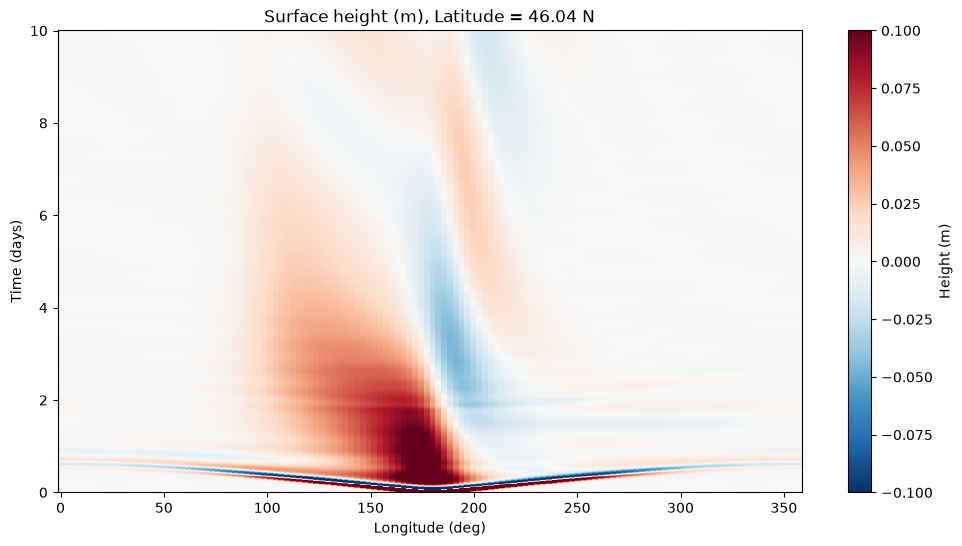

In [22]:
lon = np.degrees(phi[:, 0])            # (Nphi,)  1D longitude in degrees
t   = np.array(t_save) / day           # (nt,)    1D time in days

fig = plt.figure(figsize=(12, 6))

height = plt.pcolormesh(lon, t, h_save[:, :, itheta],
                        vmin=-0.1, vmax=0.1, cmap='RdBu_r', shading='auto')


plt.colorbar(height, label='Height (m)')
plt.xlabel('Longitude (deg)')
plt.ylabel('Time (days)')
plt.title(f'Surface height (m), Latitude = {true_lat:.2f} N')
plt.show()


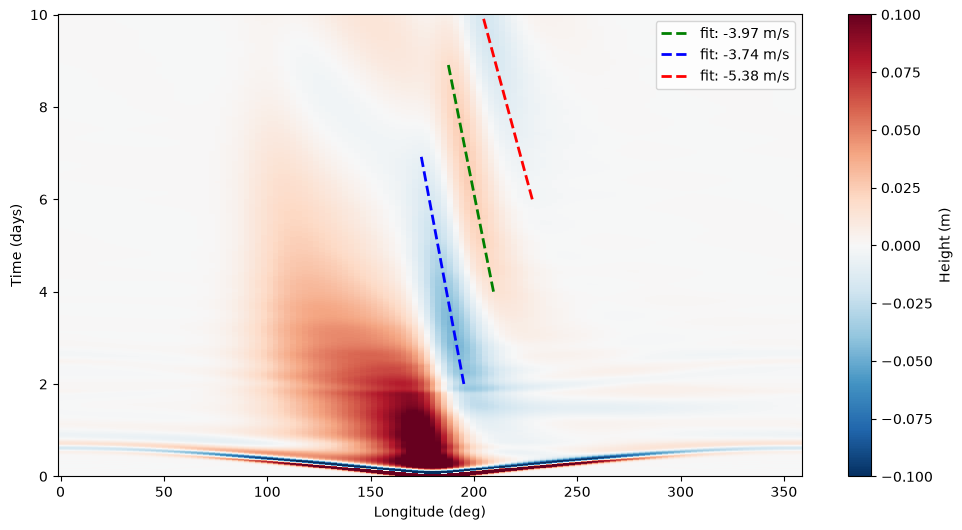

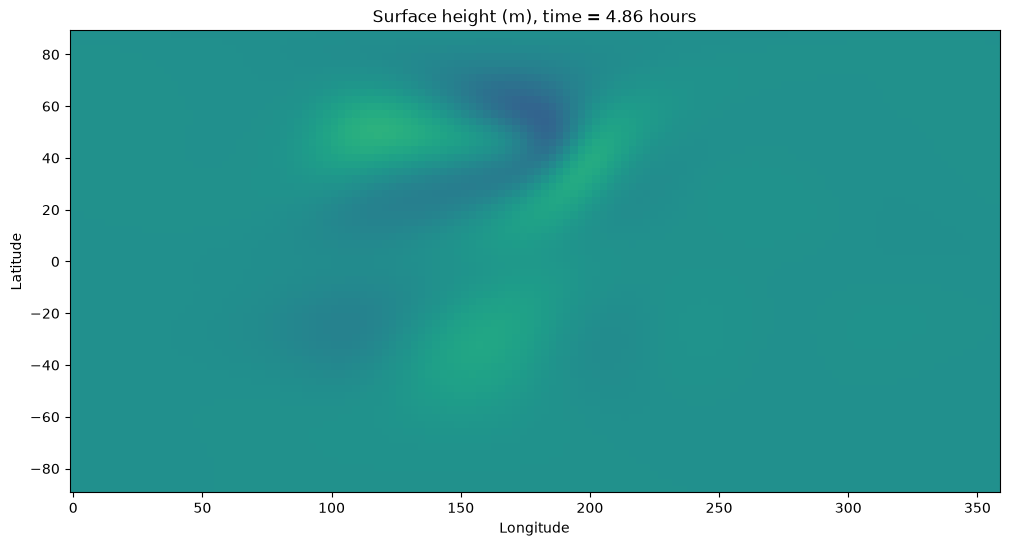

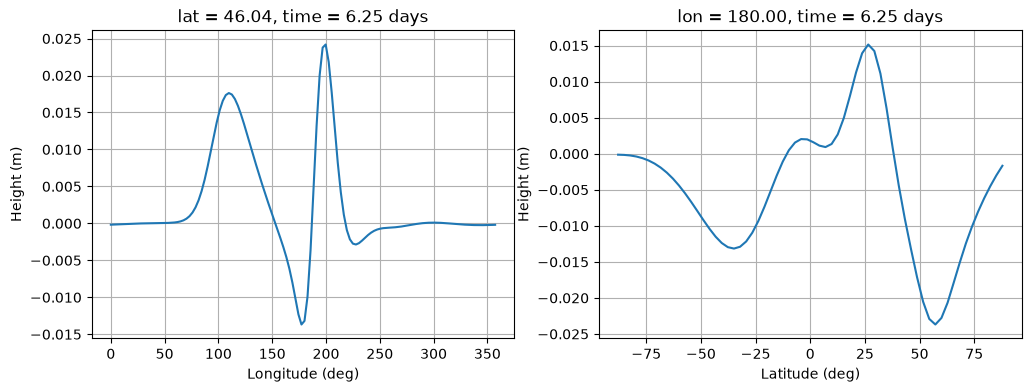

In [18]:
lon   = np.degrees(phi[:, 0])                  # (Nphi,) degrees
lat1d = 90 - np.degrees(theta[0, :])           # (Ntheta,) degrees
t     = np.array(t_save) / day                 # (nt,) days

itheta   = np.argmin(np.abs(lat1d - 45))
true_lat = lat1d[itheta]
h_lat    = h_save[:, :, itheta]                # (nt, Nphi)

deg_to_m = np.radians(1) * R * np.cos(np.radians(true_lat))   # metres per degree of longitude

t_min1, t_max1     = 2.0, 7.0       # days: after the fast gravity waves have left
lon_min1, lon_max1 = 120, 230       # degrees: inside the undamped sector (adjust after looking at the plot)
t_min2, t_max2     = 4.0, 9.0       
lon_min2, lon_max2 = 170, 250  
t_min3, t_max3     = 6.0, 10.0       
lon_min3, lon_max3 = 200, 250     

tsel1 = (t >= t_min1) & (t <= t_max1)
lsel1 = (lon >= lon_min1) & (lon <= lon_max1)
t_w1, lon_w1, h_w1 = t[tsel1], lon[lsel1], h_lat[tsel1][:, lsel1]

tsel2 = (t >= t_min2) & (t <= t_max2)
lsel2 = (lon >= lon_min2) & (lon <= lon_max2)
t_w2, lon_w2, h_w2 = t[tsel2], lon[lsel2], h_lat[tsel2][:, lsel2]

tsel3 = (t >= t_min3) & (t <= t_max3)
lsel3 = (lon >= lon_min3) & (lon <= lon_max3)
t_w3, lon_w3, h_w3 = t[tsel3], lon[lsel3], h_lat[tsel3][:, lsel3]

i_min1 = np.argmin(h_w1, axis=1)                 # trough (negative anomaly) at each time
i_max1 = np.argmax(h_w2, axis=1) 
i_min2 = np.argmin(h_w3, axis=1)                 # peak 
lon_tr1 = np.full(len(t_w1), np.nan)
lon_pk1 = np.full(len(t_w2), np.nan)
lon_tr2 = np.full(len(t_w3), np.nan)
dlon = lon[1] - lon[0]


for n, i in enumerate(i_min1):
    if 0 < i < len(lon_w1) - 1:                 # parabolic sub-grid refinement
        y0, y1, y2 = h_w1[n, i-1], h_w1[n, i], h_w1[n, i+1]
        d1 = y0 - 2*y1 + y2
        lon_tr1[n] = lon_w1[i] + (0.5*(y0 - y2)/d1*dlon if d1 != 0 else 0)
good1 = np.isfinite(lon_tr1)

(p1, cov1) = np.polyfit(t_w1[good1], lon_tr1[good1], 1, cov=True)
c1     = p1[0] * deg_to_m / day                 # m/s (negative = westward)
c1_err = np.sqrt(cov1[0, 0]) * deg_to_m / day

for n, i in enumerate(i_max1):
    if 0 < i < len(lon_w2) - 1:                 # parabolic sub-grid refinement
        y3, y4, y5 = h_w2[n, i-1], h_w2[n, i], h_w2[n, i+1]
        d2 = y3 - 2*y4 + y5
        lon_pk1[n] = lon_w2[i] + (0.5*(y3 - y5)/d2*dlon if d2 != 0 else 0)
good2 = np.isfinite(lon_pk1)

(p2, cov2) = np.polyfit(t_w2[good2], lon_pk1[good2], 1, cov=True)
c2     = p2[0] * deg_to_m / day                 # m/s (negative = westward)
c2_err = np.sqrt(cov2[0, 0]) * deg_to_m / day

for n, i in enumerate(i_min2):
    if 0 < i < len(lon_w3) - 1:                 # parabolic sub-grid refinement
        y6, y7, y8 = h_w3[n, i-1], h_w3[n, i], h_w3[n, i+1]
        d3 = y6 - 2*y7 + y8
        lon_tr2[n] = lon_w3[i] + (0.5*(y6 - y8)/d3*dlon if d3 != 0 else 0)
good3 = np.isfinite(lon_tr2)

(p3, cov3) = np.polyfit(t_w3[good3], lon_tr2[good3], 1, cov=True)
c3     = p3[0] * deg_to_m / day                 # m/s (negative = westward)
c3_err = np.sqrt(cov3[0, 0]) * deg_to_m / day


plt.figure(figsize=(12, 6))
plt.pcolormesh(lon, t, h_lat, vmin=-0.1, vmax=0.1, cmap='RdBu_r', shading='auto')
plt.colorbar(label='Height (m)')
plt.plot(p2[0]*t_w2 + p2[1], t_w2, 'g--', lw=2, label=f'fit: {c2:.2f} m/s')
plt.plot(p1[0]*t_w1 + p1[1], t_w1, 'b--', lw=2, label=f'fit: {c1:.2f} m/s')
plt.plot(p3[0]*t_w3 + p3[1], t_w3, 'r--', lw=2, label=f'fit: {c3:.2f} m/s')
plt.xlabel('Longitude (deg)'); plt.ylabel('Time (days)'); plt.legend()



# create a figure and axes
fig = plt.figure(figsize=(12,6))
# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(np.pi/2 - theta)*360/2/np.pi, np.squeeze(phi)*360/2/np.pi)  
    
plt.pcolor(Y, X, h_save[700,:,:], vmin=-0.1, vmax=0.1)
    # Specify the axis limits and labels         
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Surface height (m), time = {0:.2f} hours'.format(t[700]))


it2 = 900


plt.figure(figsize=(12,4))


plt.subplot(1, 2, 1)
plt.plot(lon, h_save[it2, :, itheta])
plt.title(f'lat = {true_lat:.2f}, time = {t[it2]:.2f} days')
plt.xlabel('Longitude (deg)')
plt.ylabel('Height (m)')
plt.grid()

plt.subplot(1, 2, 2)                       
plt.plot(lat1d, h_save[it2, 64, :])
plt.title(f'lon = {lon[64]:.2f}, time = {t[it2]:.2f} days')
plt.xlabel('Latitude (deg)')
plt.ylabel('Height (m)')
plt.grid()

plt.subplots_adjust(hspace=0.5)

In [9]:
lat_r = np.radians(true_lat)

lam_lon_deg = np.array([40, 50])     
lam_lat_deg = np.array([60, 70])     

lam_long = np.radians(lam_lon_deg) * np.cos(lat_r) * R   
lam_lat  = np.radians(lam_lat_deg) * R                   
k = 2*np.pi / lam_long
l = 2*np.pi / lam_lat

f0   = 2*Omega*np.sin(lat_r)
beta = 2*Omega*np.cos(lat_r) / R
kd   = f0**2 / (g*H)                                     

K = k[:, None]                       
L = l[None, :]                       

cpx    = -beta / (K**2 + L**2 + kd)  # (2,2): rows = lam_lon, cols = lam_lat
omega  = cpx * K
cpy    = omega / L
period = 2*np.pi / np.abs(omega) / day

print("lam_lon  lam_lat    cpx (m/s)   cpy (m/s)   period (days)")
for i, a in enumerate(lam_lon_deg):
    for j, b in enumerate(lam_lat_deg):
        print(f"{a:6d} {b:8d} {cpx[i,j]:11.2f} {cpy[i,j]:11.2f} {period[i,j]:12.1f}")

print(f"\nZonal phase speed range: {cpx.max():.2f} to {cpx.min():.2f} m/s (negative = westward)")
print(f"Period range: {period.min():.1f} to {period.max():.1f} days")

lam_lon  lam_lat    cpx (m/s)   cpy (m/s)   period (days)
    40       60       -2.98       -6.45         12.0
    40       70       -3.12       -7.87         11.4
    50       60       -4.15       -7.18         10.8
    50       70       -4.42       -8.92         10.1

Zonal phase speed range: -2.98 to -4.42 m/s (negative = westward)
Period range: 10.1 to 12.0 days


After the initial gravity wave passes and is subsequently damped, you start to see rossby waves propogating westwards. Whilst at 45N, they appear almost straight, if you look at a range of latitudes, they seem to curve. This could be due to the values for $f_0, \beta$ varying, causing different parts of the waves to travel faster or slower depending on where they are in relation to the equator. Specifically, the parts of the waves closest to the equator seem to travel quicker.

We can see that the Rossby waves have peaks and troughs in both the x and y directions - this lets us estimate k and l.

We also see the Rossby waves are not as high as the initial gravity waves, so are much fainter on the plot. 

From the longitude-time height plots at constant latitude, we can infer that the approximate westward phase velocity of the rossby waves is between about 3.7 and 5.2 m/s. we also notice that the waves rossby waves dissappear about 90 degrees E - this is due to the damping term we implemented. Intially from the video, it looked like there were still some of the residual gravity waves to begin with. On the longitude-time plot, you can see this for the first few days, so when estimating wave speed of the rossby waves in the simulation, we restricted the longitude and time frame we looked at to try and exclude these gravity wave contributions.

The dispersion relation for Rossby Waves is:
$$ \omega = \frac{-\beta k}{k^2 + l^2 + k_d^2} $$

where $\beta = 2\Omega\cos(\theta)/R$ and $k_d^2 = f_0^2/gH_0$ for $f_0 = 2\Omega\sin(\theta)$. Here, $\theta$ is latitude, R is the earth's radius, $\Omega = 2\pi$ rad/day is the angular velocity of the earth and k,l are the eastward and northward wavenumbers.

From the dispersion relation, we can calculate eastward and northward phase speed, as $c_p^x = \frac{\omega}{k}$ and $c_p^y = \frac{\omega}{l}$.

From comparing the distance between peaks and troughs in the fixed time height-lat and height-long plots above, we can guess that eastwards wavelength $\lambda_k$ is somewhere between 40 and 50 degrees and northwards wavelength $\lambda_l$ is somewhere between 60 and 70 degrees. This gives us a range of $k \in [1.63e-6 , 2.04e-6]$ and $l \in [8.07e-7 , 9.42e-7]$.

For $c_p^x$ this gives a range of speeds, from -2.98m/s with wavelengths $\lambda_k = 40$ and $\lambda_l = 60$, to -4.42m/s with wavelengths $\lambda_k = 50$ and $\lambda_l = 70$. Note, the negative sign is telling us that the wave is travelling westwards, which is what we saw from the plot of height against time and longitude.

Given that our calculated $c_p^x$ from the model was between 3.7 and 5.2 m/s, the model seems to be in good agreement with the theory, but our measured values are a bit quicke.It should be noted that we used the model to approximate k and l so the theory result is not completely independent of the model.

Some of the uncertainty in the model comes from guessing at the k and l values through a visual inspection, and we have seen that even 10 degrees in variation of k and l can change the wave speed prediction by 1.5m/s. Also, we looked at l values over a range of latitudes but only measured wave speed at a fixed latitude. In general, we have only been considering 1 latitude, ie. constant beta and f, which could have caused this discrepency.


 

## 4. Optional further investigations

* In the example of the shallow water equations on a sphere, introduce bathymetry by making $H$ a function of latitude and longitude. Make sure that you modify the equations in Dedalus appropriately. How do the waves behave when they encounter shallow water (e.g. a localized seamount)?

* It is quite difficult to simulate changing sea level (sometimes called wetting and drying), which is why the examples above do not include land. However, we can estimate the distance that a Tsunami will propagate using physical and dimensional arguments. Consider, for example, a flat, sloping beach. In the absence of energy dissipation, estimate the distance that a wave will propagate onshore. How could you modify this estimate to include energy dissipation (or drag)?